# Week 8: Network Analysis

The data are 1,478 posts from the discussion forum of one MOOC, written by 311 people.

In [1]:
%matplotlib inline
import pandas as pd, networkx as nx, matplotlib.pyplot as plt, numpy as np, itertools
from sklearn.metrics import adjusted_mutual_info_score

BASE = "https://raw.githubusercontent.com/HakeoungLee/edis8100-datasets/main/edx-mooc-forum"
posts = pd.read_csv(f"{BASE}/posts.csv")
author_of = dict(zip(posts.post_id, posts.author))

print(f"{len(posts):,} posts | {posts.author.nunique()} people | {posts.category_name.nunique()} categories")
display(posts[["author", "category_name", "parent_post_id", "title"]].head(5))

# Author ids are long hashes. Give everyone a short label so the pictures can be read.
NAME = {a: f"P{i+1:03d}" for i, a in enumerate(sorted(posts.author.dropna().unique()))}


1,478 posts | 311 people | 124 categories


,author,category_name,parent_post_id,title
0,d96db92845537eddb7c559e8de578ed12b075cad4c390a...,Week 1 / Execution Errors in Codeboard (non gr...,571f77b5d11155053000028c,NaN
1,4803b5fbbb47bd749a46cb2f873b3746e2ae6ff30a0a94...,Week 0 / 0 Introductions,NaN,INTRODUCING MYSELF..
2,f4f5300843bfd2c87a3248e731e6ec9c183e1b0eca545f...,Week 0 / 0 Introductions,571f715f7e622b05750002ae,NaN
3,f4f5300843bfd2c87a3248e731e6ec9c183e1b0eca545f...,Week 0 / 0 Introductions,NaN,Hii
4,d3e3caaf58986db9aa1cefc296f77a279b4a2e80e9eeed...,Week 0 / 0 Introductions,NaN,Welcome all


## 1. Constructing a network

The file records posts. It does not record relationships. Before any network exists, you have to specify two things: what a node represents, and what a tie represents. That specification is the tie rule.

The first rule used here is that two people are tied if one of them replied to a post written by the other. In the figure, a node is a person and its size is the person's degree, which is the number of other people they are tied to.

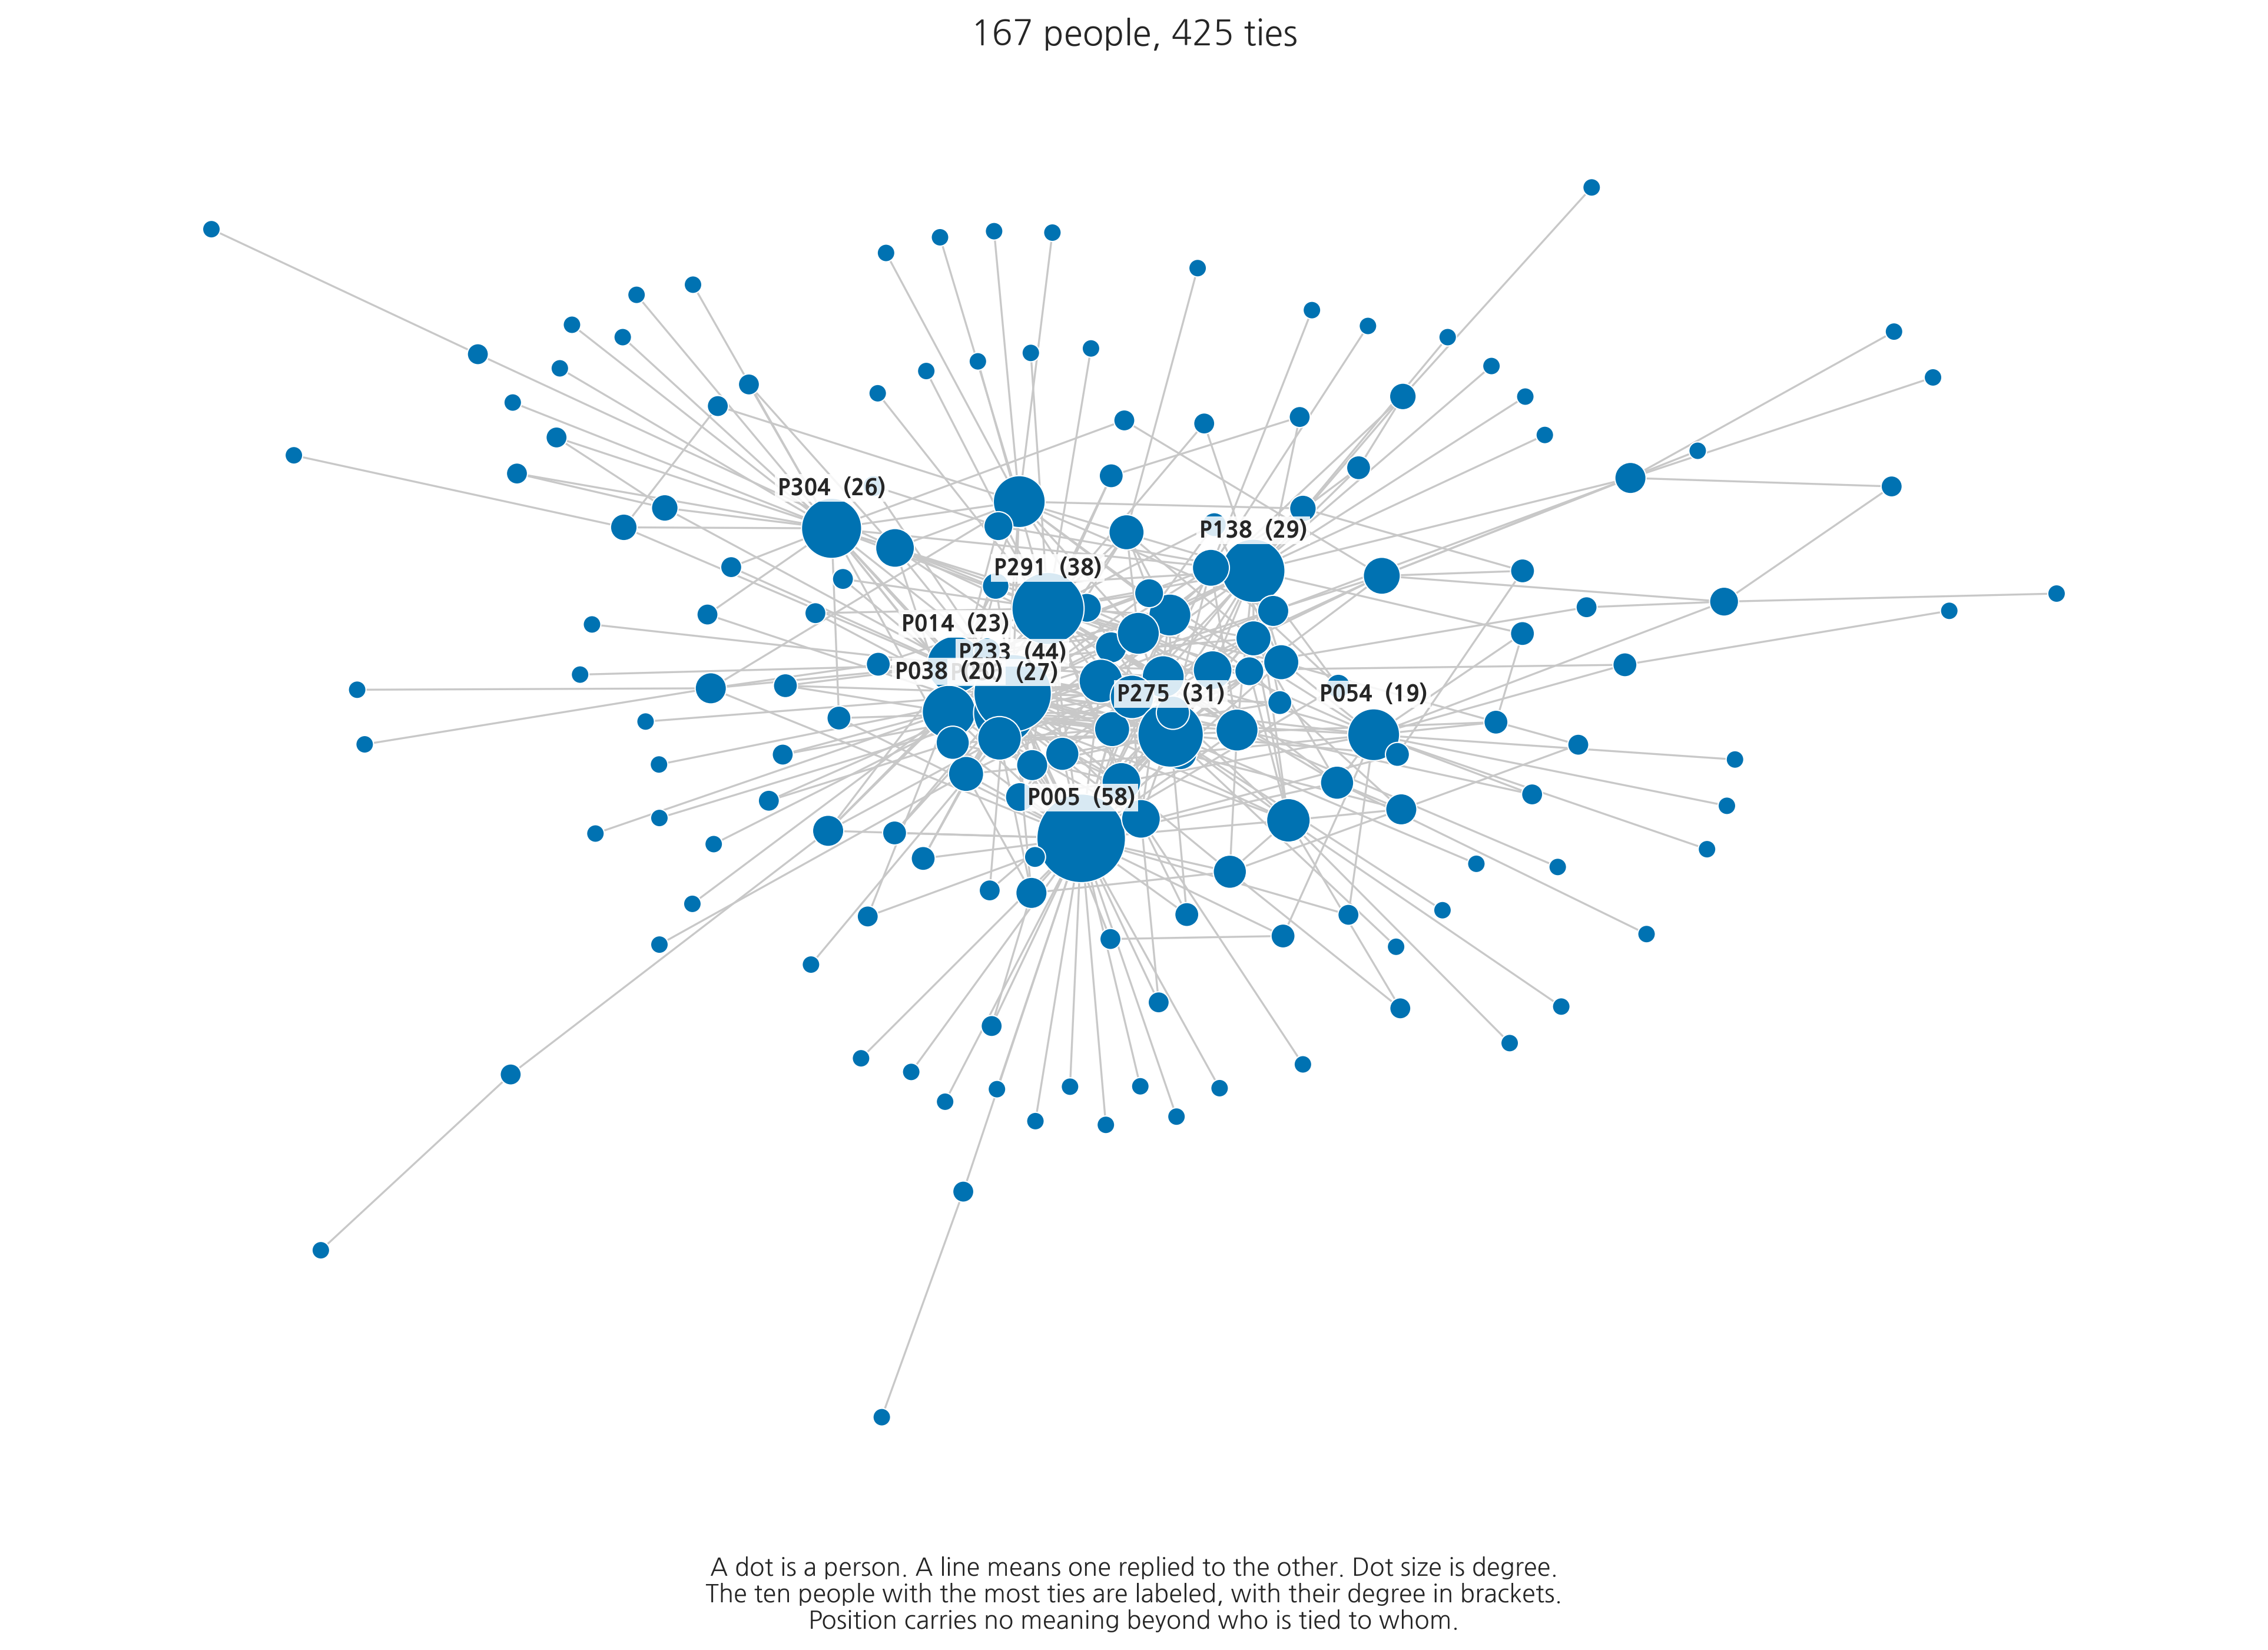

181 people made at least one tie. 130 posted and made none, so they are not here.
Degree runs from 58 down to 1. Half of them are tied to 2 people or fewer.


In [2]:
def reply_network(df):
    G = nx.Graph()
    for _, r in df.dropna(subset=["parent_post_id"]).iterrows():
        target = author_of.get(r.parent_post_id)
        if target and target != r.author:
            G.add_edge(r.author, target)
    return G

G = reply_network(posts)
LCC = G.subgraph(max(nx.connected_components(G), key=len)).copy()
pos = nx.spring_layout(LCC, seed=8100, k=0.55, iterations=300)
deg = dict(LCC.degree())
top10 = sorted(deg, key=deg.get, reverse=True)[:10]

fig, ax = plt.subplots(figsize=(13, 9.5))
nx.draw_networkx_edges(LCC, pos, ax=ax, edge_color="#c8c8c8", width=0.8)
nx.draw_networkx_nodes(LCC, pos, ax=ax, node_color="#0072b2",
                       node_size=[30 + 22 * deg[n] for n in LCC.nodes()],
                       edgecolors="white", linewidths=0.5)
for n in top10:
    x, y = pos[n]
    ax.annotate(f"{NAME[n]}  ({deg[n]})", (x, y), fontsize=9, fontweight="bold",
                textcoords="offset points", xytext=(0, 14), ha="center",
                bbox=dict(facecolor="white", alpha=.85, edgecolor="none", pad=1.2))

ax.set_title(f"{LCC.number_of_nodes()} people, {LCC.number_of_edges()} ties", fontsize=14)
ax.set_xlabel("A dot is a person. A line means one replied to the other. Dot size is degree.\n"
              "The ten people with the most ties are labeled, with their degree in brackets.\n"
              "Position carries no meaning beyond who is tied to whom.", fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

print(f"{G.number_of_nodes()} people made at least one tie. "
      f"{posts.author.nunique() - G.number_of_nodes()} posted and made none, so they are not here.")
print(f"Degree runs from {max(deg.values())} down to {min(deg.values())}. "
      f"Half of them are tied to {int(np.median(list(deg.values())))} people or fewer.")

**Takeaway**

- Of the 311 people who posted, 130 neither replied to anyone nor received a reply. They are absent from the network, and the figure gives no indication that they existed.
- Degree ranges from 58 to 1, and half the people in the network are tied to two others or fewer. The structure is dominated by a small number of participants.
- The spatial arrangement of the figure carries no information. Only the presence and absence of ties is interpretable.

Three things to examine in the figure.

1. The ten labeled nodes relative to the rest. Consider what share of the forum's ties is held by this small number of people.
2. The nodes on the periphery, each connected by a single line. Consider what pattern of participation produces a degree of 1.
3. The center of the figure. Consider whether it appears to be one group or several.

## 2. Varying the tie rule

A tie rule has two components: the definition of a node and the definition of a tie. In the three networks below the node definition is held constant, so that each network contains the same people who posted. Only the tie definition changes.

1. One person replied to a post written by the other.
2. Both posted in the same thread.
3. Both posted in the same category.

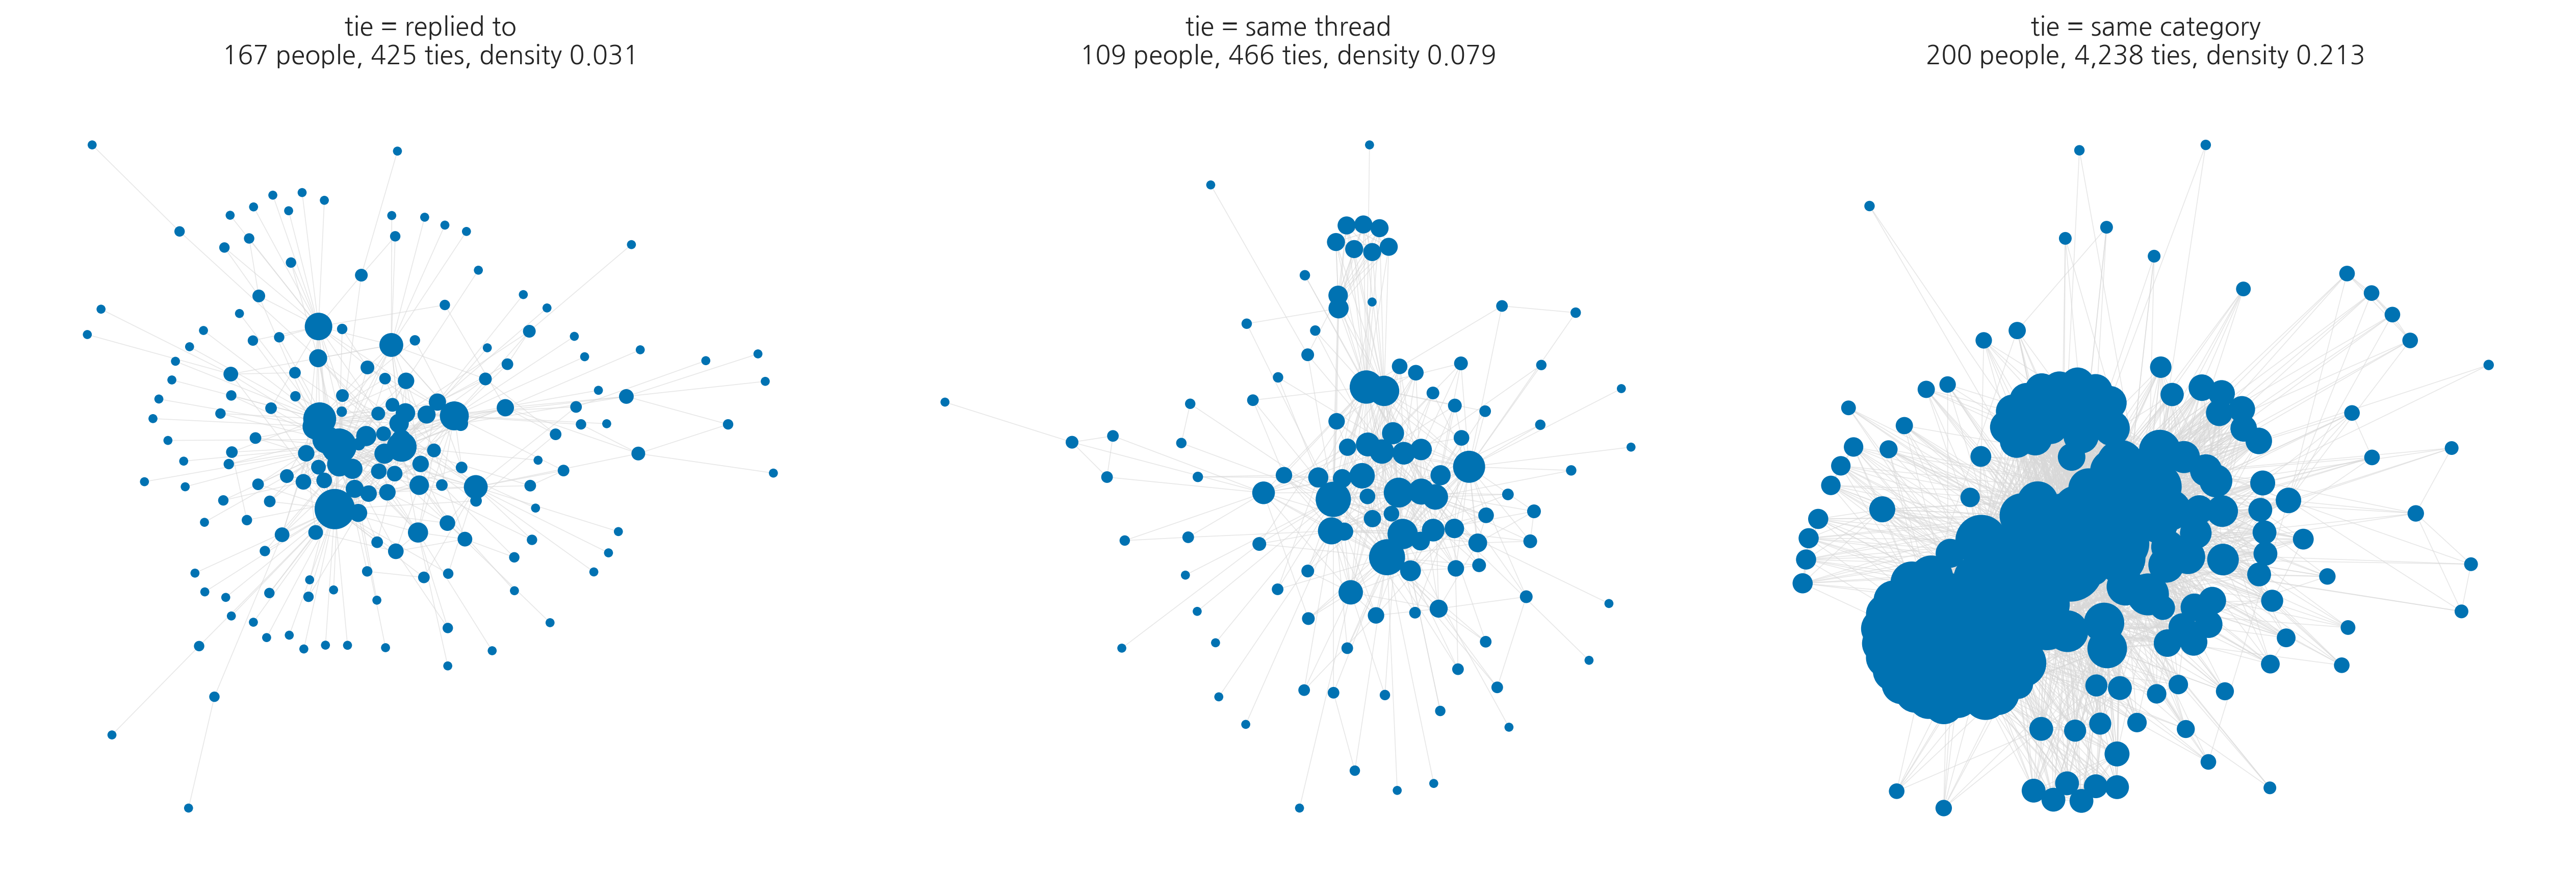

In [3]:
# A rule has two parts: what counts as a node, and what counts as a tie.
# Here the nodes are always the people who posted. Only the tie changes.

def tie_by_reply(df):
    "tie two people if one replied to the other"
    G = nx.Graph()
    for _, r in df.dropna(subset=["parent_post_id"]).iterrows():
        t = author_of.get(r.parent_post_id)
        if t and t != r.author:
            G.add_edge(r.author, t)
    return G

def tie_by_sharing(df, column, cap=120):
    "tie two people if they both posted under the same value of this column"
    G = nx.Graph()
    for _, g in df.groupby(column):
        people = sorted(set(g.author.dropna()))
        if len(people) <= cap:
            G.add_edges_from(itertools.combinations(people, 2))
    return G


nets = {
    "replied to":      tie_by_reply(posts),
    "same thread":     tie_by_sharing(posts, "thread_id"),
    "same category":   tie_by_sharing(posts, "category_name"),
}

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, (name, H) in zip(axes, nets.items()):
    K = H.subgraph(max(nx.connected_components(H), key=len)).copy()
    p = nx.spring_layout(K, seed=8100, k=0.5, iterations=200)
    d = dict(K.degree())
    nx.draw_networkx_edges(K, p, ax=ax, edge_color="#d8d8d8", width=0.4, alpha=.6)
    nx.draw_networkx_nodes(K, p, ax=ax, node_color="#0072b2",
                           node_size=[12 + 6 * d[n] for n in K.nodes()], linewidths=0)
    ax.set_title(f"tie = {name}\n{K.number_of_nodes()} people, {K.number_of_edges():,} ties, "
                 f"density {nx.density(K):.3f}", fontsize=12)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Takeaway**

- The three rules produce networks whose density ranges from 0.03 to 0.21, although the underlying posts are identical.
- Replying to a person and posting in the same category are different relational claims, and neither rule is more correct than the other in general.
- The tie rule is a methodological decision taken before any measure is computed, and it constrains every result that follows.

The three networks are built from the same 1,478 posts. Consider which of the three rules you would adopt, and for which research question.

## 3. Community detection

A community is a set of nodes that are tied to one another more densely than to the rest of the network. The algorithm identifies them from the tie structure alone.

In the figure, consider whether the labeled nodes sit at the center of their own community or at its boundary, and whether any community has few ties to the others.

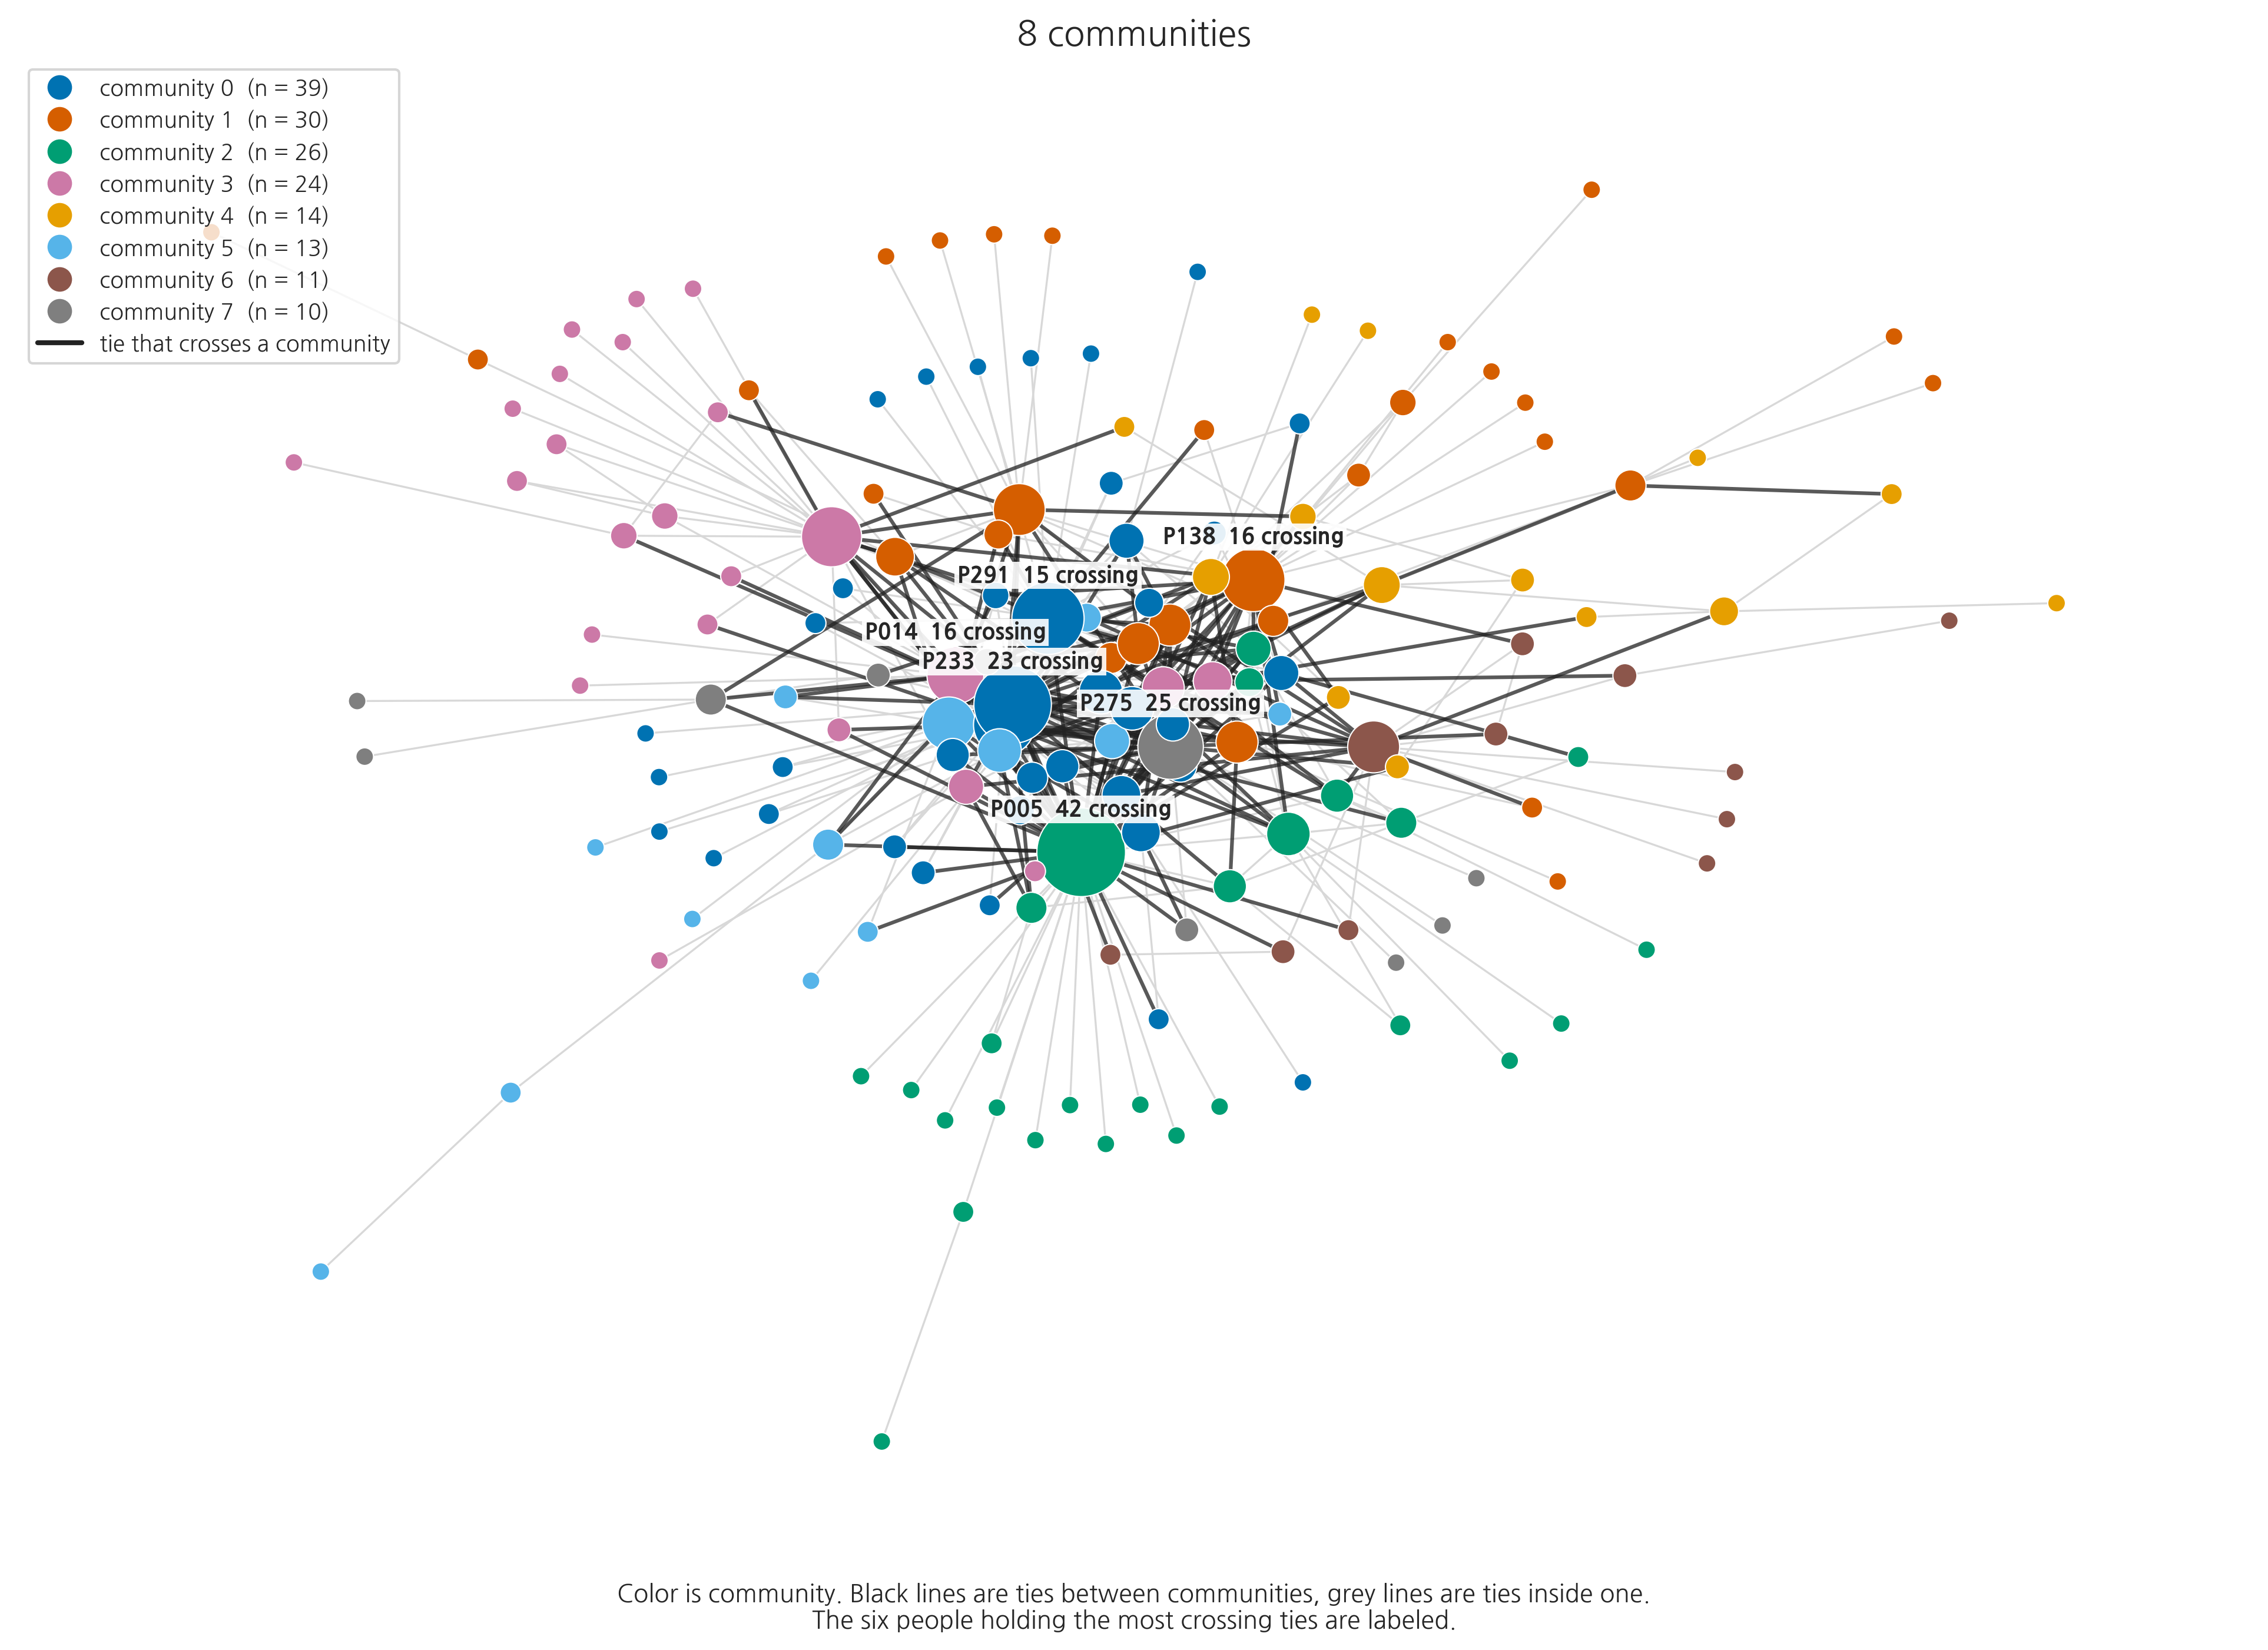

community sizes: [39, 30, 26, 24, 14, 13, 11, 10]
199 of 425 ties cross a community line.


In [4]:
communities = list(nx.community.greedy_modularity_communities(LCC))
community_of = {n: i for i, c_ in enumerate(communities) for n in c_}
COLORS = ["#0072b2", "#d55e00", "#009e73", "#cc79a7", "#e69f00", "#56b4e9", "#8c564b", "#7f7f7f"]

within = [(a, b) for a, b in LCC.edges() if community_of[a] == community_of[b]]
across  = [(a, b) for a, b in LCC.edges() if community_of[a] != community_of[b]]

# who holds the most ties that leave their own community
crossing = pd.Series(0, index=list(LCC.nodes()))
for a, b in across:
    crossing[a] += 1; crossing[b] += 1
bridges = crossing.nlargest(6).index.tolist()

fig, ax = plt.subplots(figsize=(13, 9.5))
nx.draw_networkx_edges(LCC, pos, edgelist=within, ax=ax, edge_color="#d8d8d8", width=0.8)
nx.draw_networkx_edges(LCC, pos, edgelist=across, ax=ax, edge_color="#222222", width=1.5, alpha=.75)
nx.draw_networkx_nodes(LCC, pos, ax=ax,
                       node_color=[COLORS[community_of[n] % len(COLORS)] for n in LCC.nodes()],
                       node_size=[30 + 22 * deg[n] for n in LCC.nodes()],
                       edgecolors="white", linewidths=0.5)
for n in bridges:
    x, y = pos[n]
    ax.annotate(f"{NAME[n]}  {crossing[n]} crossing", (x, y), fontsize=9, fontweight="bold",
                textcoords="offset points", xytext=(0, 15), ha="center",
                bbox=dict(facecolor="white", alpha=.9, edgecolor="none", pad=1.2))

handles = [plt.Line2D([], [], marker="o", ls="", ms=9, color=COLORS[i % len(COLORS)],
                      label=f"community {i}  (n = {len(c_)})") for i, c_ in enumerate(communities)]
handles.append(plt.Line2D([], [], color="#222222", lw=2, label="tie that crosses a community"))
ax.legend(handles=handles, fontsize=9, loc="upper left", frameon=True)

ax.set_title(f"{len(communities)} communities", fontsize=14)
ax.set_xlabel("Color is community. Black lines are ties between communities, grey lines are ties inside one.\n"
              "The six people holding the most crossing ties are labeled.", fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

print("community sizes:", [len(c_) for c_ in communities])
print(f"{len(across)} of {LCC.number_of_edges()} ties cross a community line.")

**Takeaway**

- 199 of the 425 ties connect members of different communities, so the detected groups are not separated from one another.
- The algorithm returns a partition for any network, including one in which ties have been assigned at random. The presence of eight communities is therefore not evidence of group structure.
- The participants holding the largest numbers of crossing ties are located near the center of the figure, not between two communities.

## 4. Testing what the communities correspond to

The forum organizes posts into categories. If the detected communities correspond to topics, the members of a community should post predominantly within a single category.

The table reports, for each community, the category its members used most. Examine the community with the closest correspondence and the one with the weakest, and consider what each community could reasonably be called.

In [5]:
main_category = (posts.groupby(["author", "category_name"]).size().reset_index(name="n")
                 .sort_values("n", ascending=False).drop_duplicates("author")
                 .set_index("author").category_name.to_dict())

rows = []
for i, c in enumerate(communities):
    cats = pd.Series([main_category[n] for n in c if n in main_category]).value_counts()
    rows.append({"community": i, "people": len(c),
                 "most common category": cats.index[0],
                 "how many of them": f"{cats.iloc[0]} of {cats.sum()}"})
display(pd.DataFrame(rows))

nodes = [n for n in LCC.nodes() if n in main_category]
score = adjusted_mutual_info_score([community_of[n] for n in nodes],
                                   [main_category[n] for n in nodes])
print(f"\nAgreement between communities and categories: {score:.3f}")
print("(0 is what you get from unrelated groupings, 1 is a perfect match.)")

,community,people,most common category,how many of them
0,0,39,Week 2 / Exam 2,4 of 39
1,1,30,Week 0 / 0 Introductions,6 of 25
2,2,26,Week 0 / 0 Introductions,6 of 26
3,3,24,Any Question? / General,12 of 24
4,4,14,Any Questions? / Technical Help,3 of 13
5,5,13,Week 0 / 0 Introductions,4 of 13
6,6,11,Any Question? / General,3 of 11
7,7,10,Any Question? / General,2 of 10



Agreement between communities and categories: 0.070
(0 is what you get from unrelated groupings, 1 is a perfect match.)


**Takeaway**

- Agreement between the detected communities and the forum categories is 0.07, where 0 is the value expected from two unrelated groupings.
- The communities therefore do not correspond to topics. Whatever produced these groupings, it was not the subject matter of the posts.
- The algorithm assigns no meaning to the partitions it returns. Any interpretation of a community is supplied by the analyst.

## 5. Comparing degree against a simple count

Poquet and Joksimovic (2022) report that in studies of online learner interaction, centrality frequently functions as a proxy for a participant's level of activity rather than as an indicator of their position relative to others.

The cell below ranks every person twice, once by degree and once by the number of posts they wrote, and reports where the two rankings disagree.

The top 10 by degree, and where a post count would have put them:


,degree,posts written,rank by degree,rank by posts,moved
0,58.0,132,1,1,0
1,44.0,89,2,2,0
2,38.0,57,3,4,1
3,31.0,82,4,3,-1
4,29.0,48,5,6,1
5,27.0,56,6,5,-1
6,26.0,33,7,8,1
7,23.0,25,8,9,1
8,20.0,40,9,7,-2
9,19.0,19,10,13,3



The people who move most:


,degree,posts written,rank by degree,rank by posts,moved
0,3.0,1,57,119,62
1,2.0,1,74,119,45
2,2.0,1,74,119,45
3,2.0,1,74,119,45
4,2.0,1,74,119,45
5,2.0,1,74,119,45
6,2.0,1,74,119,45
7,2.0,1,74,119,45


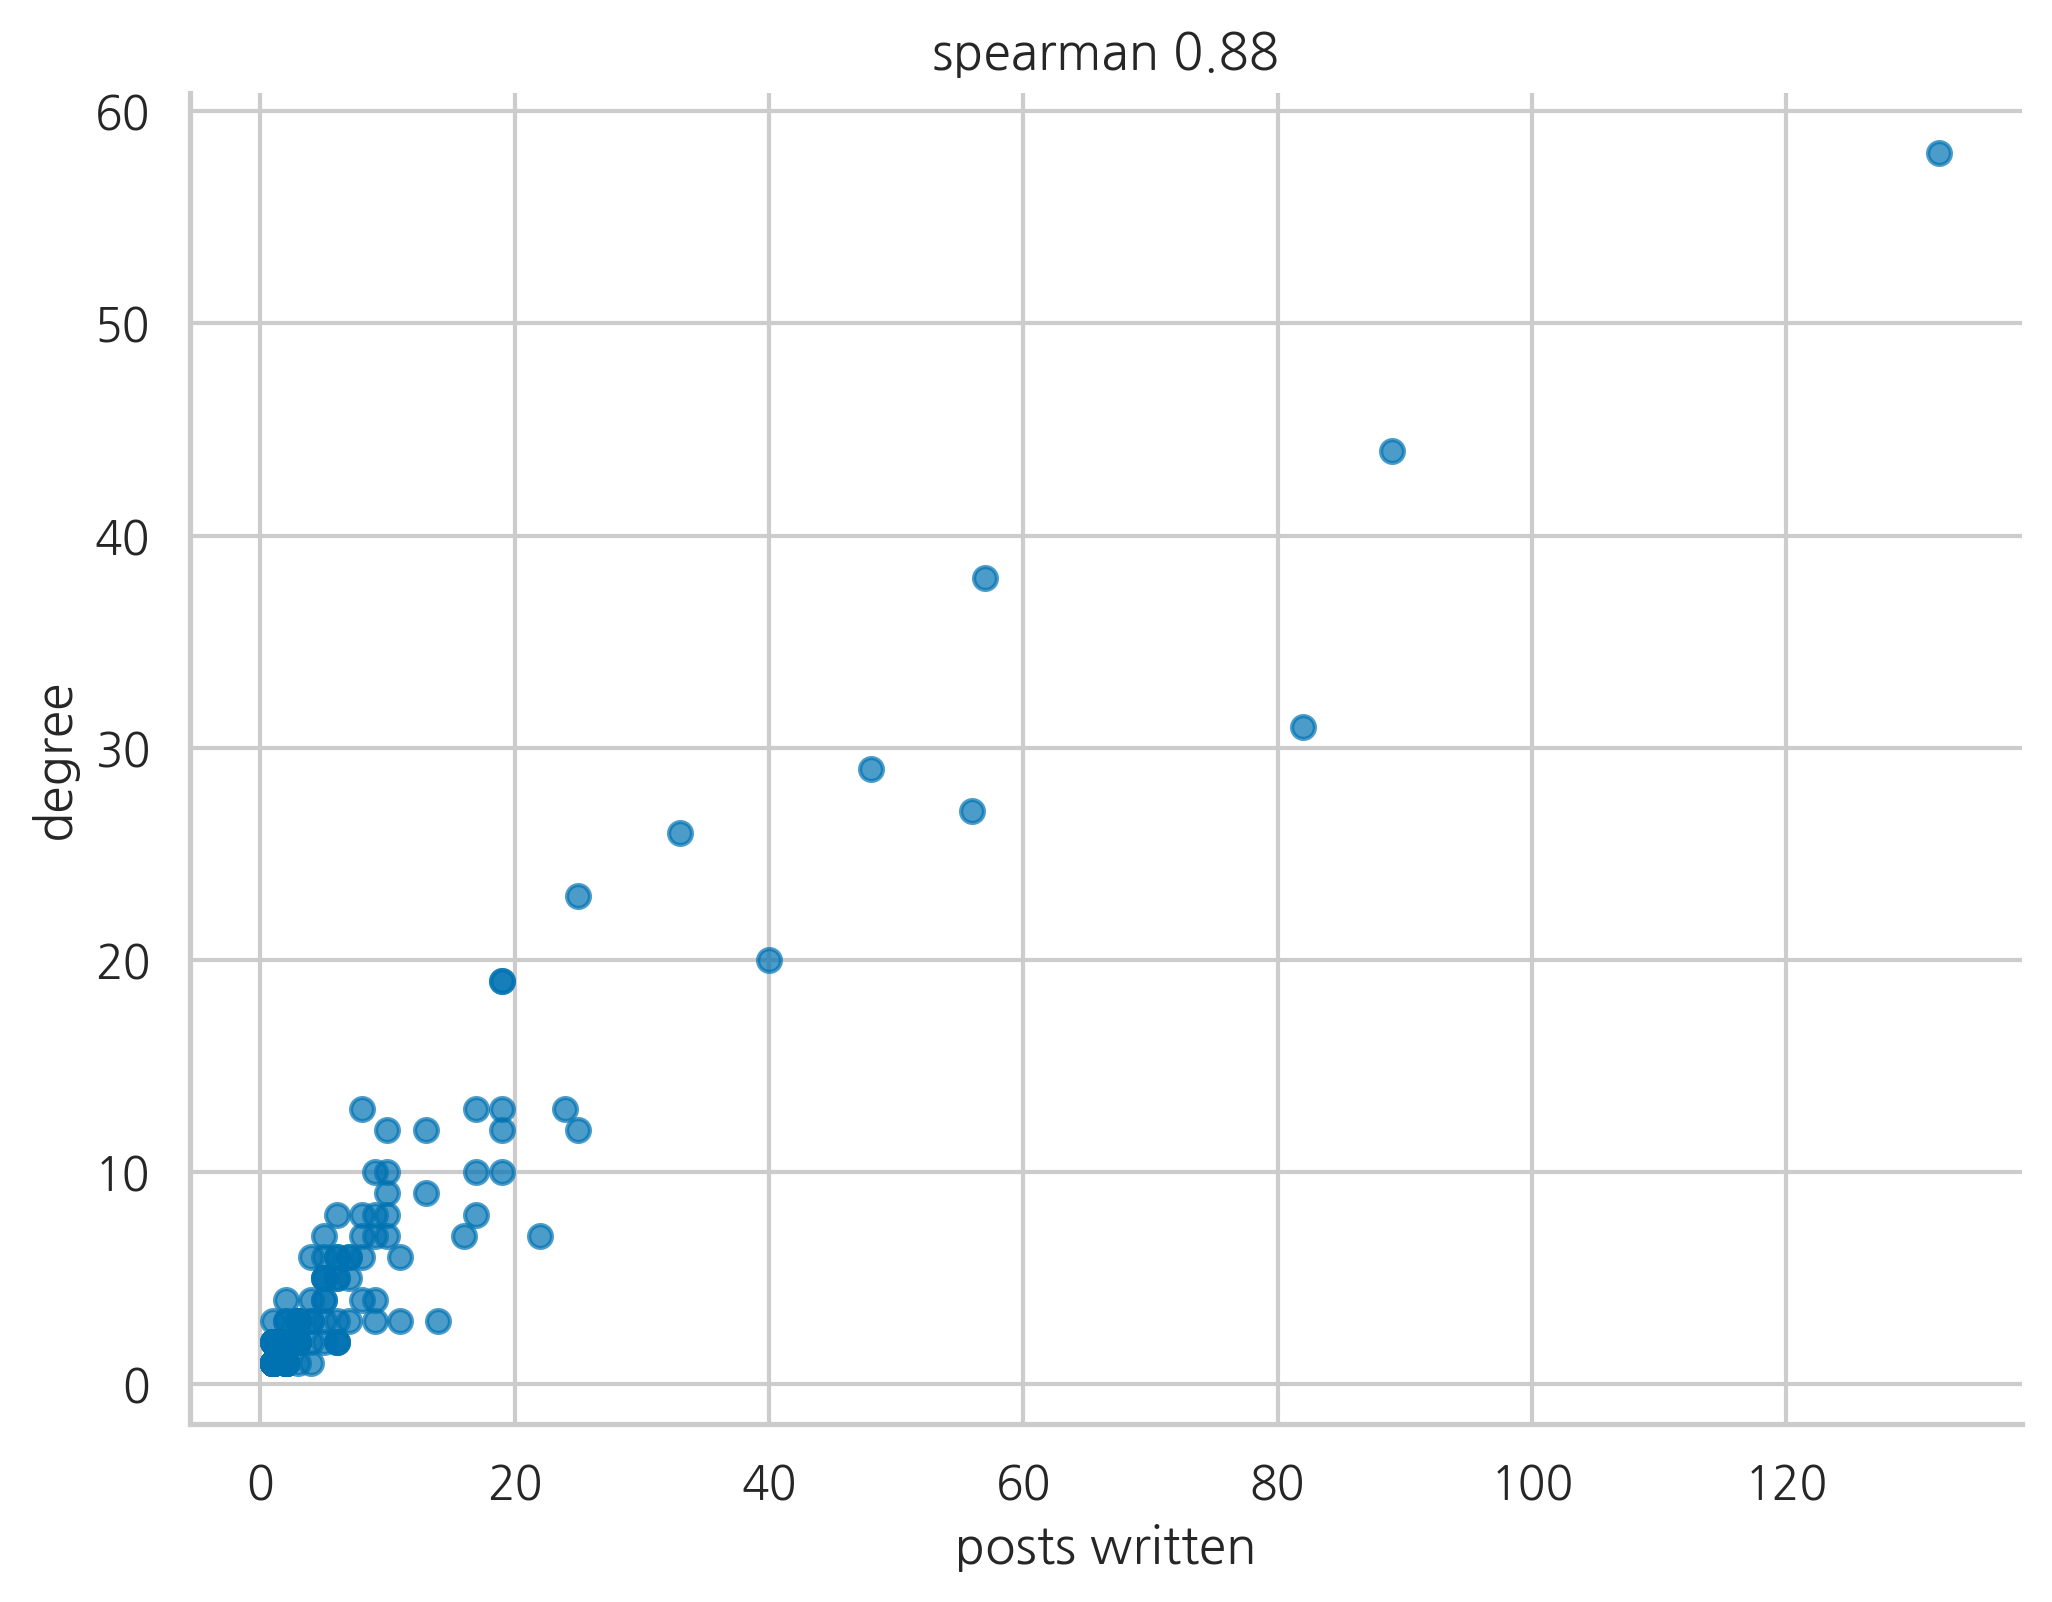

In [6]:
cent = pd.DataFrame({
    "degree": pd.Series(deg),
    "posts written": posts.author.value_counts(),
}).dropna()
cent["rank by degree"] = cent.degree.rank(ascending=False, method="min").astype(int)
cent["rank by posts"]  = cent["posts written"].rank(ascending=False, method="min").astype(int)
cent["moved"] = cent["rank by posts"] - cent["rank by degree"]

print("The top 10 by degree, and where a post count would have put them:")
display(cent.nsmallest(10, "rank by degree").reset_index(drop=True))

print("\nThe people who move most:")
display(cent.reindex(cent.moved.abs().sort_values(ascending=False).index)
            .head(8).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(cent["posts written"], cent.degree, s=30, color="#0072b2", alpha=.7)
ax.set_xlabel("posts written"); ax.set_ylabel("degree")
ax.set_title(f"spearman {cent.degree.corr(cent['posts written'], method='spearman'):.2f}", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Takeaway**

- Degree and post count correlate at 0.88, and the ten highest-degree participants shift by at most three ranks when ordered by post count. A simple count would have identified almost the same people.
- The participants whose rankings differ most are at the lower end of both distributions, with a single post and two or three ties.
- This is the pattern Poquet and Joksimovic describe. Before reporting a centrality measure, establish what it contributes beyond a count that is already available.

## 6. The passage of time

Molenaar and Wise (2022) separate two concepts of time. The **passage of time** treats time as a continuous flow of events and is indexed by four metrics: position, duration, frequency and rate. **Order in time** concerns the organization among events, and is described in terms of consistency, recurrent and non-recurrent change, and irregular change.

The network built in sections 1 to 5 uses neither. A reply written in the first week and one written in the tenth contribute the same tie.

The figure below reports frequency, the simplest of the four passage metrics.

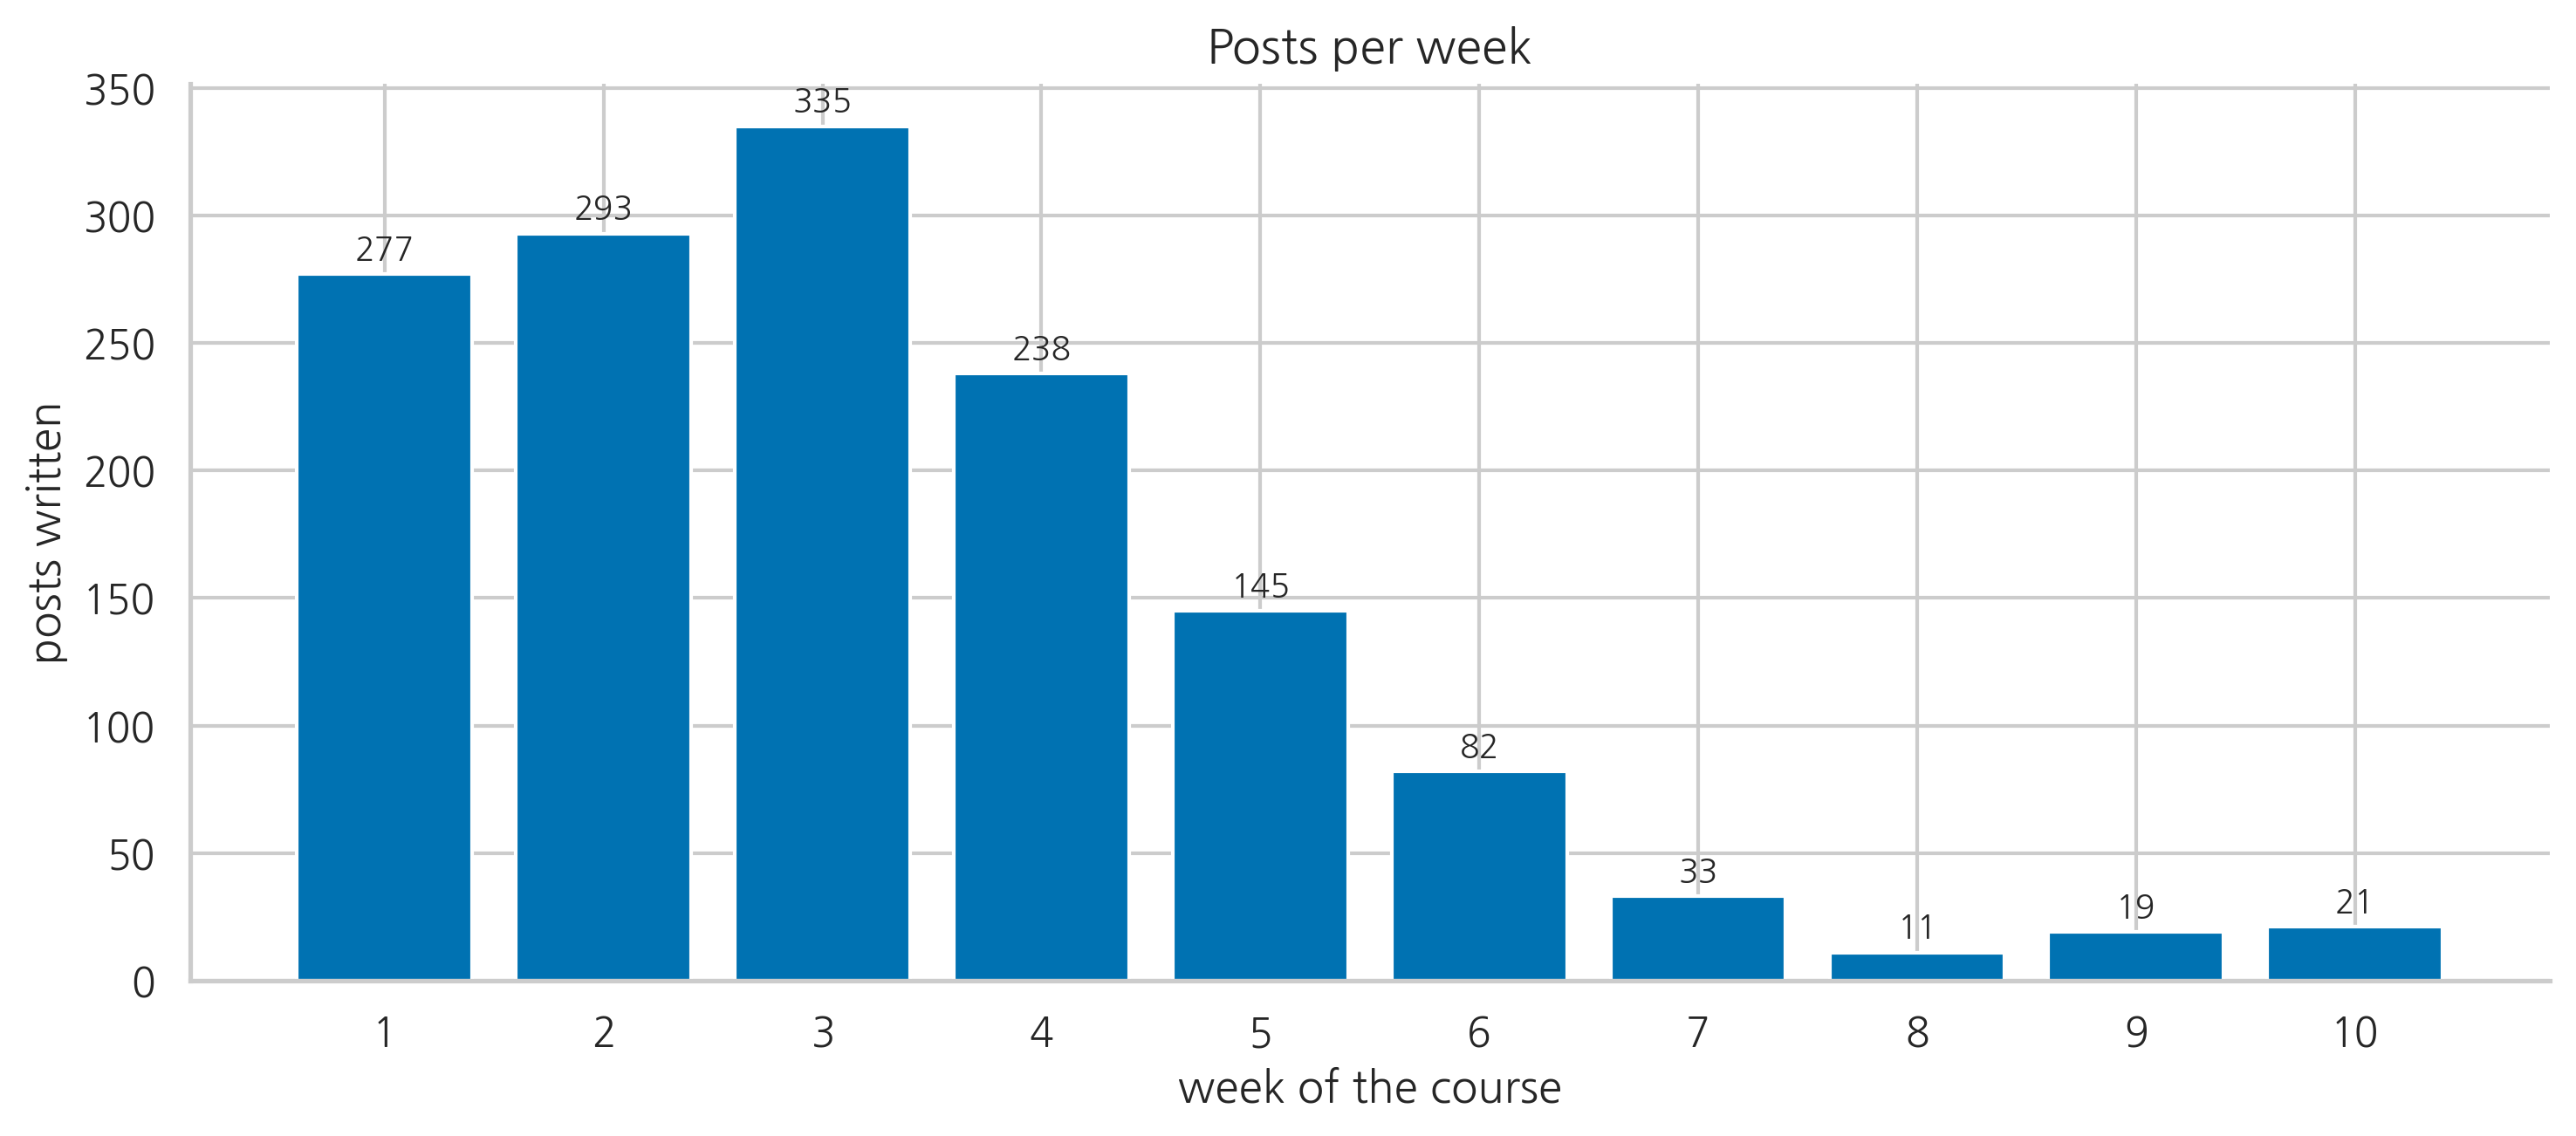

The course ran from 2016-04-26. 905 of the 1,478 posts were written in the first three weeks.


In [7]:
posts["t"] = pd.to_datetime(posts.time, errors="coerce")
start = posts.t.min()
posts["week"] = ((posts.t - start).dt.days // 7) + 1
weekly = posts[posts.week <= 10].week.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(weekly.index, weekly.values, color="#0072b2")
for w, n in weekly.items():
    ax.text(w, n + 6, str(n), ha="center", fontsize=9)
ax.set_xticks(range(1, 11))
ax.set_xlabel("week of the course"); ax.set_ylabel("posts written")
ax.set_title("Posts per week", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

print(f"The course ran from {start.date()}. "
      f"{int(weekly.iloc[:3].sum())} of the {len(posts):,} posts were written in the first three weeks.")

**Takeaway**

- Posting falls from 335 in week 3 to 11 in week 8. Any measure computed over the full period is dominated by the opening weeks.
- 206 of the 298 people who posted did so in a single week, so for most participants there is no temporal pattern to describe.
- The network in sections 1 to 5 treats these ten weeks as one interval and gives a tie the same value whether it came from someone present throughout or someone present once.

## 7. Order in time

Order in time concerns the arrangement of **different kinds of events** relative to one another. Molenaar and Wise distinguish four arrangements: **consistency**, where the same events repeat; **regular recurrent change**, where a particular ordering of different event types occurs repeatedly; **non-recurrent regular change**, where the same ordering appears across people but once each; and **irregular change**, where no ordering is discernible.

This forum records three kinds of event. A person can start a thread, write a response to a thread, or comment on a response. The figure below reports, for everyone who posted at least twice, what they did next after each kind of post.

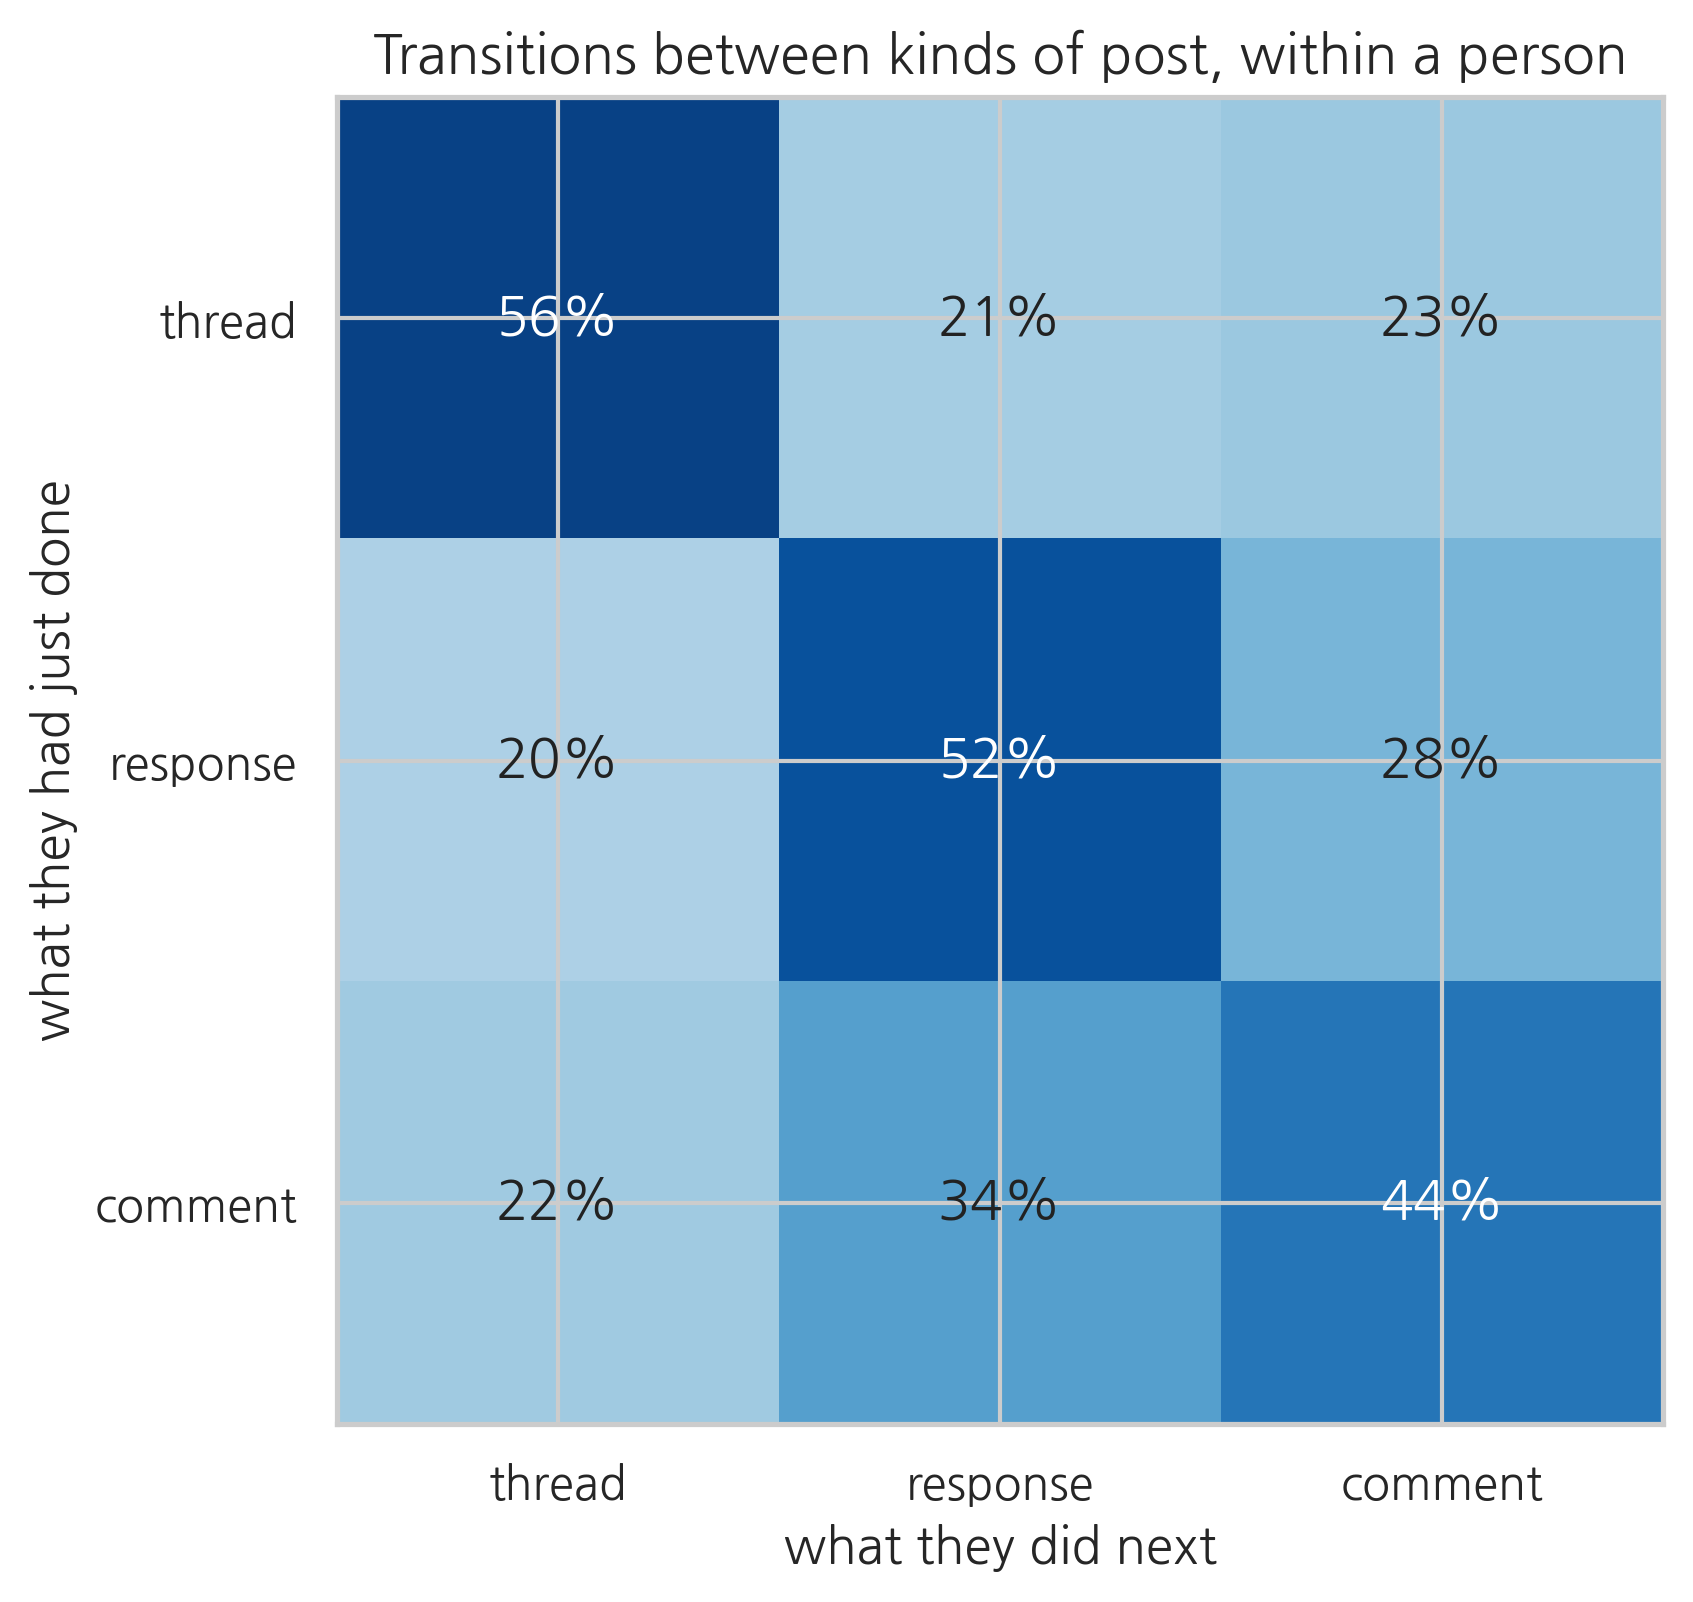

142 of 311 people posted at least twice and appear in this figure.


,thread,response,comment
thread,231,88,94
response,82,218,117
comment,75,114,148


In [8]:
seq = posts.sort_values("t")
trans = {}
for _, g in seq.groupby("author"):
    s = list(g.post_type)
    for x, y in zip(s[:-1], s[1:]):
        trans[(x, y)] = trans.get((x, y), 0) + 1

order = ["thread", "response", "comment"]
M = pd.Series(trans).unstack().reindex(index=order, columns=order).fillna(0)
pct = M.div(M.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(pct.values, cmap="Blues", vmin=0, vmax=60)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{pct.iloc[i, j]:.0f}%", ha="center", va="center", fontsize=13,
                color="white" if pct.iloc[i, j] > 35 else "#222222")
ax.set_xticks(range(3)); ax.set_xticklabels(order)
ax.set_yticks(range(3)); ax.set_yticklabels(order)
ax.set_xlabel("what they did next"); ax.set_ylabel("what they had just done")
ax.set_title("Transitions between kinds of post, within a person", fontsize=13)
plt.tight_layout(); plt.show()

print(f"{int((posts.groupby('author').size() >= 2).sum())} of {posts.author.nunique()} people "
      f"posted at least twice and appear in this figure.")
display(M.astype(int))

**Takeaway**

- Every row has its largest value on the diagonal. After starting a thread, 56 percent of next posts are another thread; after a response, 52 percent are another response.
- In the chapter's terms this is consistency, the repetition of the same kind of event, rather than regular recurrent change. No ordering between different event types recurs here.
- 142 of the 311 people posted more than once. For the remaining 169 there is no sequence, so the figure describes under half the forum.

## 8. When people arrived, and where they ended up

Sections 1 to 5 drew the network with no reference to time, so a person who joined in week 1 and a person who joined in week 7 appear the same way. The figure below is the same network, colored by the week in which each person first posted.

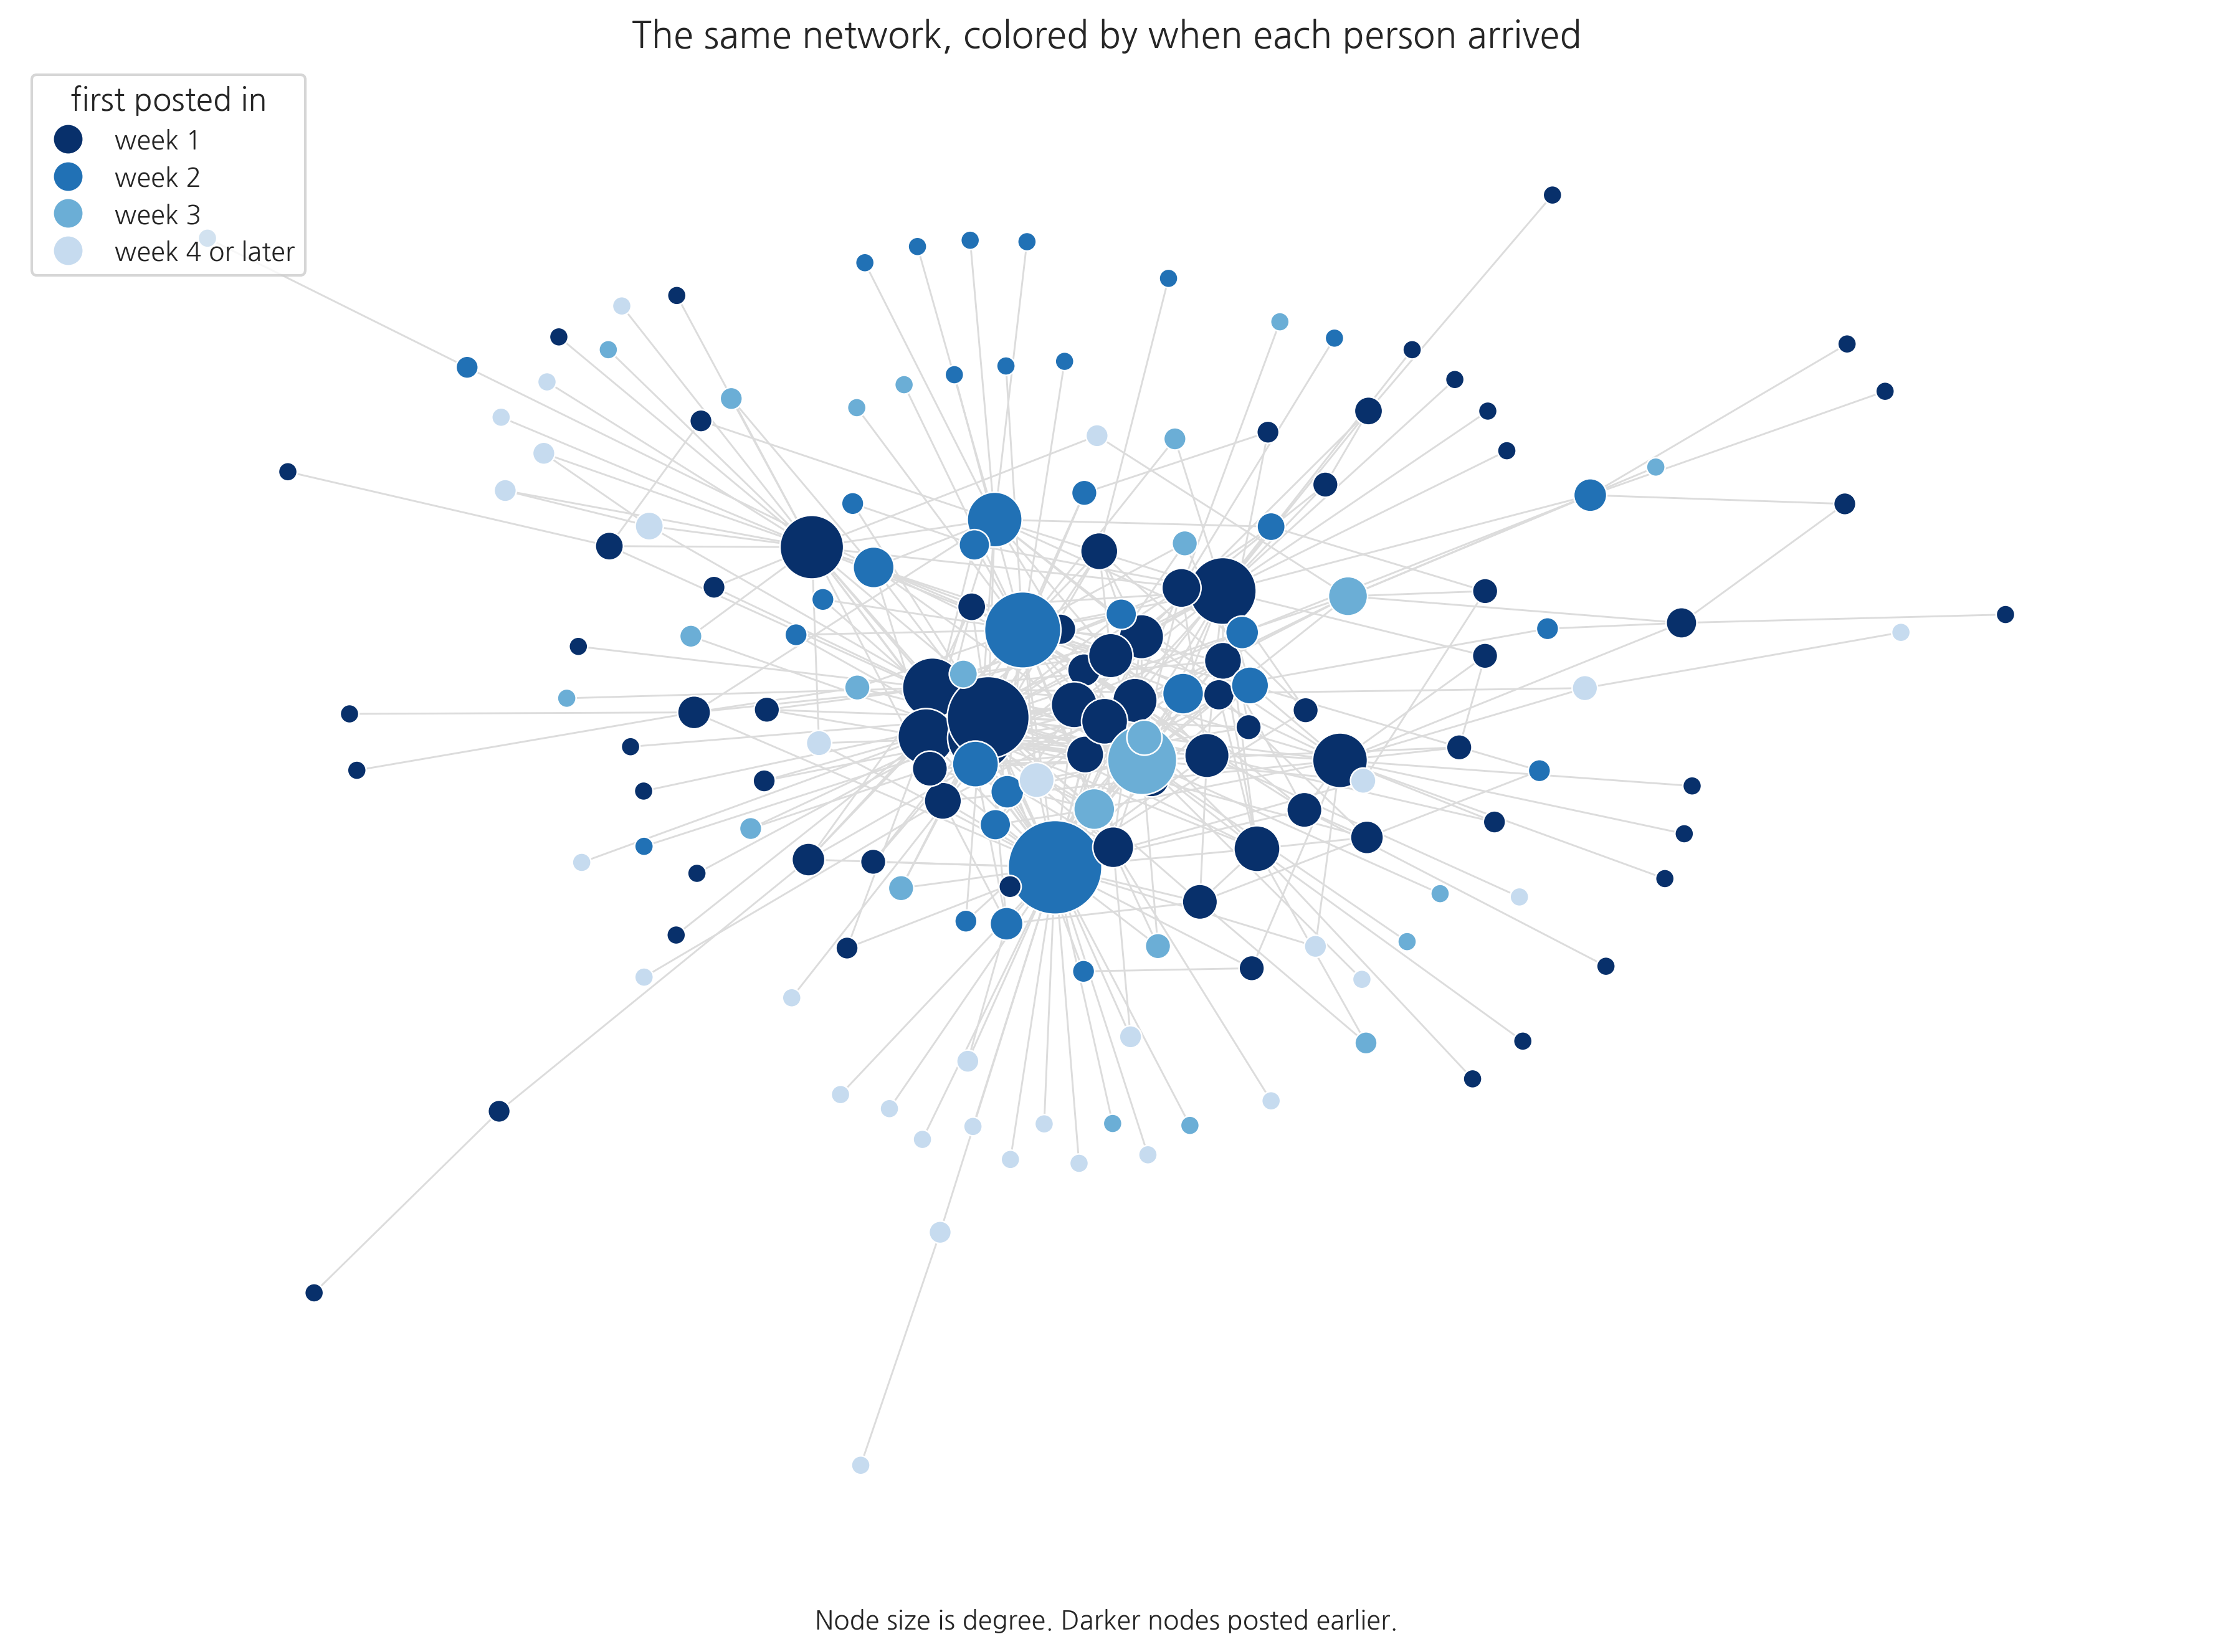

,people,mean_degree
first posted in week,,
1,77,6.2
2,35,6.5
3,24,3.9
4,8,1.5
5,5,2.6
6,4,1.5


In [9]:
first_week = posts.groupby("author").week.min()
arrival = pd.Series({n: first_week.get(n, np.nan) for n in LCC.nodes()})
band = arrival.clip(upper=4)          # weeks 4 and later are grouped
SHADES = {1: "#08306b", 2: "#2171b5", 3: "#6baed6", 4: "#c6dbef"}
LABEL  = {1: "week 1", 2: "week 2", 3: "week 3", 4: "week 4 or later"}

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(LCC, pos, ax=ax, edge_color="#dcdcdc", width=0.7)
nx.draw_networkx_nodes(LCC, pos, ax=ax,
                       node_color=[SHADES[int(band[n])] for n in LCC.nodes()],
                       node_size=[30 + 22 * deg[n] for n in LCC.nodes()],
                       edgecolors="white", linewidths=0.6)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=10, color=SHADES[k],
                              label=LABEL[k]) for k in [1, 2, 3, 4]],
          fontsize=10, loc="upper left", frameon=True, title="first posted in")
ax.set_title("The same network, colored by when each person arrived", fontsize=14)
ax.set_xlabel("Node size is degree. Darker nodes posted earlier.", fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

summary = (pd.DataFrame({"first posted in week": arrival, "degree": pd.Series(deg)})
           .groupby("first posted in week")
           .agg(people=("degree", "size"), mean_degree=("degree", "mean")).round(1))
display(summary.head(6))

**Takeaway**

- People who arrived in weeks 1 and 2 hold a mean degree of 6.2 and 6.5. From week 4 onward the mean is between 1.5 and 2.6.
- The later arrivals sit on the periphery. Joining a forum that already has a structure is not the same as helping to build one.
- None of this is visible in the figures in sections 1 to 5, which were drawn from the same ties. Adding time to a network changes what the same picture supports.

## Returning to the text

The networks above were constructed entirely from the structure of replies. None of the measures used the content of any post. The cell below retrieves the posts written by one person.

In [10]:
WHO = cent.nsmallest(1, "rank by degree").index[0]   # change to any author id

print(f"{deg[WHO]} ties, {int(cent.loc[WHO, 'posts written'])} posts\n")
for _, r in posts[posts.author == WHO].head(12).iterrows():
    print(f"[{r.category_name}] {str(r.body)[:150]}")

58 ties, 132 posts

[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] And this is what is incorrectly marked as correct:     ![failure trace error][1]     [1]: https://edxuploads.s3.amazonaws.com/14626129267029983.png
[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] The wording of the question is misleading.        The expected values in the test itself are not correct → the question should read :     What are/wou
[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] Thank you florina - the text is much clearer now!
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.     → Any negative input will lead to a stack overflow     → Negative inputs are lega
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.   → Any negative input will lead to a stack overflow      → Negative inputs are legal
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.    → Any negati

Three questions to close.

1. Consider whether the participant with the highest degree is also the most consequential participant in the forum, and what evidence would settle that.
2. The three rules in section 2 produced three different networks. Consider what determines which rule is appropriate for a given question.
3. Consider what took place in this forum that none of these networks can represent.